In [1]:

# Week 4 - Day 5: Data Preprocessing
# Titanic Dataset - Initial Setup

import pandas as pd
import numpy as np

# Load the Titanic dataset directly from GitHub
url = (
    "https://raw.githubusercontent.com/"
    "avialazraki/DI_Bootcamp/main/"
    "Week4/Day4/ExerciseXP/train.csv"
)

df = pd.read_csv(url)

# Display basic dataset information
print("Titanic dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())


Titanic dataset loaded successfully!
Dataset shape: (891, 12)

First 5 rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [2]:

# Exercise 1: Duplicate Detection and Removal

# Count rows before removing duplicates
rows_before = len(df)

# Identify duplicate rows across all columns
duplicate_count = df.duplicated().sum()

print("Rows before cleaning:", rows_before)
print("Duplicate rows found:", duplicate_count)

# Remove duplicate rows and create a clean copy
df = df.drop_duplicates().copy()

# Count rows after removing duplicates
rows_after = len(df)

print("Rows after cleaning:", rows_after)
print("Rows removed:", rows_before - rows_after)

# Verify that no duplicate rows remain
print("Remaining duplicates:", df.duplicated().sum())


Rows before cleaning: 891
Duplicate rows found: 0
Rows after cleaning: 891
Rows removed: 0
Remaining duplicates: 0


In [3]:

# Exercise 2: Handling Missing Values
# Step 1 - Identify missing values

print("Missing values in each column:")
print(df.isnull().sum())

# Calculate the percentage of missing values
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print("\nPercentage of missing values:")
print(missing_percentage)

# Display only columns containing missing values
missing_columns = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage
})

print("\nColumns requiring attention:")
display(missing_columns[missing_columns["Missing Count"] > 0])


Missing values in each column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Percentage of missing values:
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64

Columns requiring attention:


,Missing Count,Missing Percentage
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


In [5]:

# Exercise 2: Handling Missing Values
# Step 2 - Apply different cleaning strategies

from sklearn.impute import SimpleImputer

# 1. AGE: Fill missing values with the median.
# Median is less sensitive to extreme ages than the mean.
age_imputer = SimpleImputer(strategy="median")
df["Age"] = age_imputer.fit_transform(df[["Age"]]).ravel()

# 2. CABIN: Replace missing values with "Unknown".
# Cabin information is missing for many passengers.
# Keeping "Unknown" preserves these passenger records.
df["Cabin"] = df["Cabin"].fillna("Unknown")

# 3. EMBARKED: Remove rows with missing embarkation ports.
# Only two records are missing, so removal has little impact.
rows_before = len(df)
df = df.dropna(subset=["Embarked"]).copy()

print("Rows removed due to missing Embarked:", rows_before - len(df))

# Verify missing values after cleaning
print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nFinal dataset shape:", df.shape)


Rows removed due to missing Embarked: 2

Missing values after cleaning:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

Final dataset shape: (889, 12)


In [6]:

# Exercise 3: Feature Engineering
# Step 1 - Create new features

# FamilySize includes the passenger, siblings/spouse,
# and parents/children traveling aboard.
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

# Extract passenger titles from names
# Example: "Braund, Mr. Owen Harris" -> "Mr"
df["Title"] = df["Name"].str.extract(
    r",\s*([^.]*)\."
)[0].str.strip()

# Display the new features
print("New features created successfully!")

display(
    df[[
        "Name",
        "SibSp",
        "Parch",
        "FamilySize",
        "Title"
    ]].head(10)
)

# Check title distribution
print("\nTitle distribution:")
print(df["Title"].value_counts())

print("\nUpdated dataset shape:", df.shape)


New features created successfully!


,Name,SibSp,Parch,FamilySize,Title
0,"Braund, Mr. Owen Harris",1,0,2,Mr
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0,2,Mrs
2,"Heikkinen, Miss. Laina",0,0,1,Miss
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0,2,Mrs
4,"Allen, Mr. William Henry",0,0,1,Mr
5,"Moran, Mr. James",0,0,1,Mr
6,"McCarthy, Mr. Timothy J",0,0,1,Mr
7,"Palsson, Master. Gosta Leonard",3,1,5,Master
8,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",0,2,3,Mrs
9,"Nasser, Mrs. Nicholas (Adele Achem)",1,0,2,Mrs



Title distribution:
Title
Mr              517
Miss            181
Mrs             124
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

Updated dataset shape: (889, 14)


In [7]:

# Exercise 3: Feature Engineering
# Step 2 - Encode the Title feature

# One-hot encoding creates a separate column for each title.
# We retain the original Title column for later analysis.

title_encoded = pd.get_dummies(
    df["Title"],
    prefix="Title",
    dtype=int
)

# Add encoded title columns to the dataset
df = pd.concat([df, title_encoded], axis=1)

print("Title encoding completed successfully!")

print("\nNew encoded columns:")
print(title_encoded.columns.tolist())

print("\nFirst 5 rows:")
display(title_encoded.head())

print("\nUpdated dataset shape:", df.shape)


Title encoding completed successfully!

New encoded columns:
['Title_Capt', 'Title_Col', 'Title_Don', 'Title_Dr', 'Title_Jonkheer', 'Title_Lady', 'Title_Major', 'Title_Master', 'Title_Miss', 'Title_Mlle', 'Title_Mme', 'Title_Mr', 'Title_Mrs', 'Title_Ms', 'Title_Rev', 'Title_Sir', 'Title_the Countess']

First 5 rows:


,Title_Capt,Title_Col,Title_Don,Title_Dr,Title_Jonkheer,Title_Lady,Title_Major,Title_Master,Title_Miss,Title_Mlle,Title_Mme,Title_Mr,Title_Mrs,Title_Ms,Title_Rev,Title_Sir,Title_the Countess
0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
2,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0



Updated dataset shape: (889, 31)


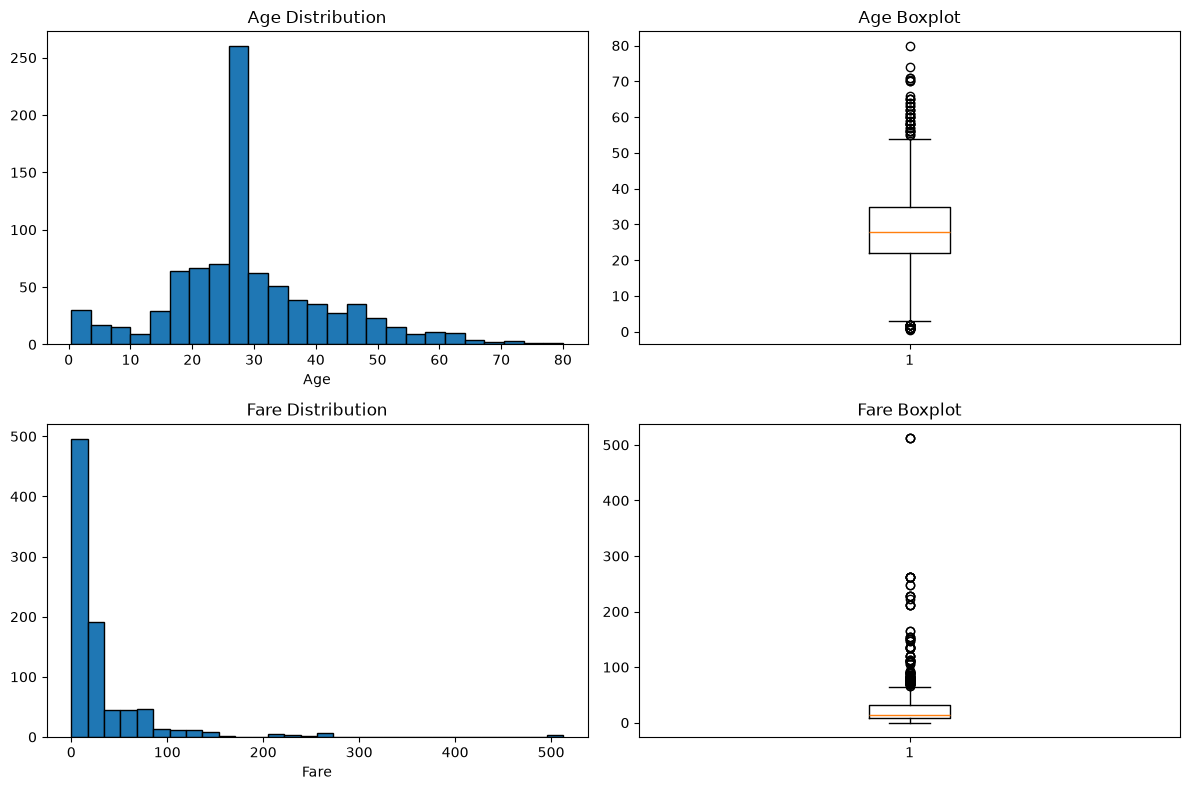

Age statistics:
count    889.000000
mean      29.315152
std       12.984932
min        0.420000
25%       22.000000
50%       28.000000
75%       35.000000
max       80.000000
Name: Age, dtype: float64

Fare statistics:
count    889.000000
mean      32.096681
std       49.697504
min        0.000000
25%        7.895800
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64


In [9]:

# Exercise 4: Outlier Detection and Handling
# Step 1 - Visualize Age and Fare distributions

import matplotlib.pyplot as plt

# Visualize the Age and Fare distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Age histogram
axes[0, 0].hist(df["Age"], bins=25, edgecolor="black")
axes[0, 0].set_title("Age Distribution")
axes[0, 0].set_xlabel("Age")

# Age boxplot
axes[0, 1].boxplot(df["Age"])
axes[0, 1].set_title("Age Boxplot")

# Fare histogram
axes[1, 0].hist(df["Fare"], bins=30, edgecolor="black")
axes[1, 0].set_title("Fare Distribution")
axes[1, 0].set_xlabel("Fare")

# Fare boxplot
axes[1, 1].boxplot(df["Fare"])
axes[1, 1].set_title("Fare Boxplot")

plt.tight_layout()
plt.show()

print("Age statistics:")
print(df["Age"].describe())

print("\nFare statistics:")
print(df["Fare"].describe())


In [10]:

# Exercise 4: Outlier Detection
# Step 2 - Detect outliers using the IQR method

def detect_outliers_iqr(data, column):
    # Calculate the first and third quartiles
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)

    # Calculate the interquartile range
    iqr = q3 - q1

    # Use the standard 1.5 * IQR rule
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Identify values outside the bounds
    outliers = data[
        (data[column] < lower_bound) |
        (data[column] > upper_bound)
    ]

    print(f"\n--- {column} ---")
    print(f"Q1: {q1:.2f}")
    print(f"Q3: {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower bound: {lower_bound:.2f}")
    print(f"Upper bound: {upper_bound:.2f}")
    print(f"Potential outliers: {len(outliers)}")

    return outliers

# Detect potential outliers
age_outliers = detect_outliers_iqr(df, "Age")
fare_outliers = detect_outliers_iqr(df, "Fare")



--- Age ---
Q1: 22.00
Q3: 35.00
IQR: 13.00
Lower bound: 2.50
Upper bound: 54.50
Potential outliers: 65

--- Fare ---
Q1: 7.90
Q3: 31.00
IQR: 23.10
Lower bound: -26.76
Upper bound: 65.66
Potential outliers: 114


In [11]:

# Exercise 4: Outlier Handling
# Step 3 - Cap extreme values without removing rows

# Save original values for comparison
df["Fare_Original"] = df["Fare"]
df["Age_Original"] = df["Age"]

# Fare: cap values above the 98th percentile
# This reduces the influence of very expensive tickets.
fare_cap = df["Fare"].quantile(0.98)

df["Fare"] = df["Fare"].clip(upper=fare_cap)

# Age: calculate IQR bounds
q1 = df["Age"].quantile(0.25)
q3 = df["Age"].quantile(0.75)
iqr = q3 - q1

age_lower = q1 - 1.5 * iqr
age_upper = q3 + 1.5 * iqr

# Cap Age within the observed range and IQR bounds
df["Age"] = df["Age"].clip(
    lower=max(0, age_lower),
    upper=age_upper
)

# Compare before and after treatment
print("Fare cap (98th percentile):", round(fare_cap, 2))
print("Age upper bound:", round(age_upper, 2))

print("\nBefore and after outlier treatment:")
display(
    df[[
        "Fare_Original",
        "Fare",
        "Age_Original",
        "Age"
    ]].describe()
)

print("\nDataset shape:", df.shape)


Fare cap (98th percentile): 211.34
Age upper bound: 54.5

Before and after outlier treatment:


,Fare_Original,Fare,Age_Original,Age
count,889.000000,889.000000,889.000000,889.000000
mean,32.096681,30.567524,29.315152,29.000562
std,49.697504,39.881074,12.984932,12.051609
min,0.000000,0.000000,0.420000,2.500000
25%,7.895800,7.895800,22.000000,22.000000
50%,14.454200,14.454200,28.000000,28.000000
75%,31.000000,31.000000,35.000000,35.000000
max,512.329200,211.337500,80.000000,54.500000



Dataset shape: (889, 33)


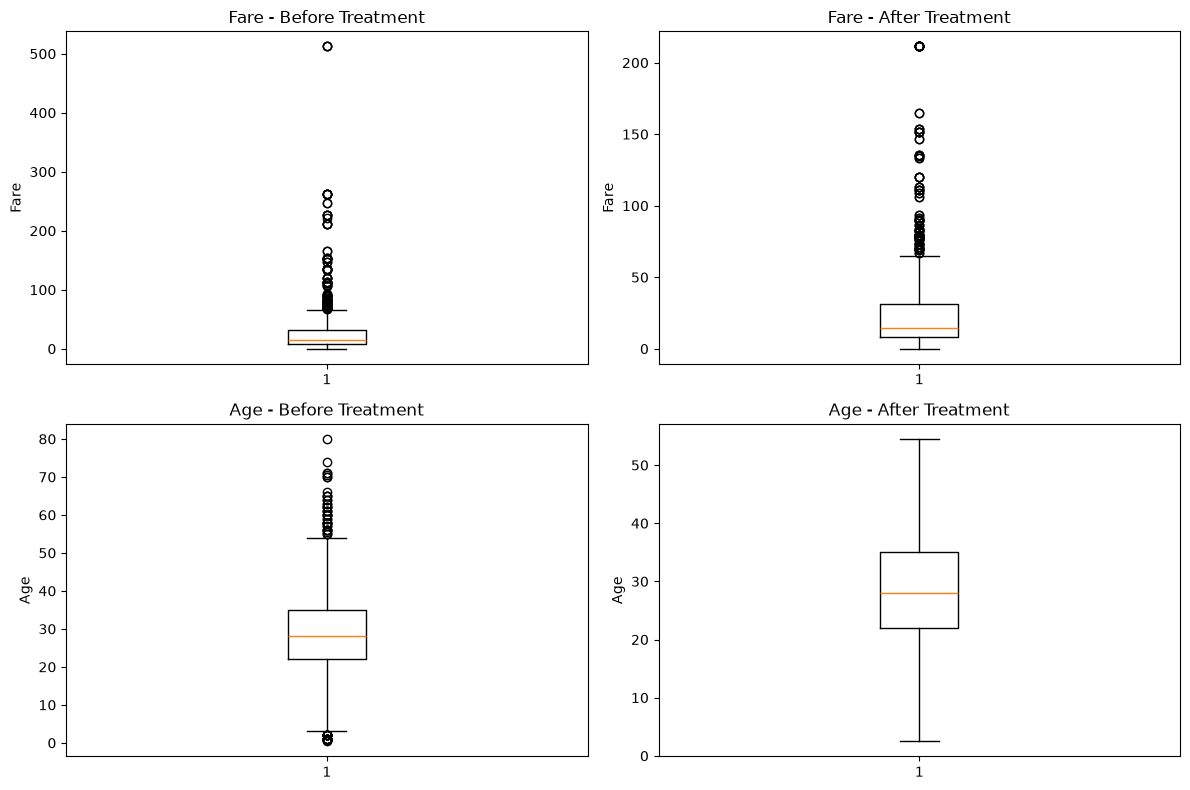

Passengers with adjusted fares: 17
Passengers with adjusted ages: 65
Remaining passengers: 889


In [12]:

# Exercise 4: Outlier Handling
# Step 4 - Compare distributions before and after treatment

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Fare before treatment
axes[0, 0].boxplot(df["Fare_Original"])
axes[0, 0].set_title("Fare - Before Treatment")
axes[0, 0].set_ylabel("Fare")

# Fare after treatment
axes[0, 1].boxplot(df["Fare"])
axes[0, 1].set_title("Fare - After Treatment")
axes[0, 1].set_ylabel("Fare")

# Age before treatment
axes[1, 0].boxplot(df["Age_Original"])
axes[1, 0].set_title("Age - Before Treatment")
axes[1, 0].set_ylabel("Age")

# Age after treatment
axes[1, 1].boxplot(df["Age"])
axes[1, 1].set_title("Age - After Treatment")
axes[1, 1].set_ylabel("Age")

plt.tight_layout()
plt.show()

# Confirm which values changed
print("Passengers with adjusted fares:",
      (df["Fare_Original"] != df["Fare"]).sum())

print("Passengers with adjusted ages:",
      (df["Age_Original"] != df["Age"]).sum())

print("Remaining passengers:", len(df))


In [13]:

# Exercise 5: Data Standardization and Normalization
# Step 1 - Standardization using StandardScaler

from sklearn.preprocessing import StandardScaler

# Select numerical features for standardization
standard_columns = ["Age", "FamilySize"]

# Initialize StandardScaler
standard_scaler = StandardScaler()

# Fit and transform selected columns
standardized_values = standard_scaler.fit_transform(
    df[standard_columns]
)

# Create new standardized columns
df["Age_Standardized"] = standardized_values[:, 0]
df["FamilySize_Standardized"] = standardized_values[:, 1]

# Display results
print("Standardization completed successfully!")

display(
    df[[
        "Age",
        "Age_Standardized",
        "FamilySize",
        "FamilySize_Standardized"
    ]].head(10)
)

# Verify mean and standard deviation
print("\nStandardized feature statistics:")
print(
    df[[
        "Age_Standardized",
        "FamilySize_Standardized"
    ]].agg(["mean", "std"]).round(4)
)


Standardization completed successfully!


,Age,Age_Standardized,FamilySize,FamilySize_Standardized
0,22.0,-0.581209,2,0.057853
1,38.0,0.747162,2,0.057853
2,26.0,-0.249116,1,-0.561804
3,35.0,0.498092,2,0.057853
4,35.0,0.498092,1,-0.561804
5,28.0,-0.083070,1,-0.561804
6,54.0,2.075533,1,-0.561804
7,2.5,-2.200161,5,1.916826
8,27.0,-0.166093,3,0.677511
9,14.0,-1.245394,2,0.057853



Standardized feature statistics:
      Age_Standardized  FamilySize_Standardized
mean            0.0000                   0.0000
std             1.0006                   1.0006


In [14]:

# Exercise 5: Data Standardization and Normalization
# Step 2 - Normalization using MinMaxScaler

from sklearn.preprocessing import MinMaxScaler

# Initialize MinMaxScaler
minmax_scaler = MinMaxScaler()

# Normalize Fare to the range [0, 1]
df["Fare_Normalized"] = minmax_scaler.fit_transform(
    df[["Fare"]]
).ravel()

print("Fare normalization completed successfully!")

# Compare original and normalized Fare
display(
    df[[
        "Fare",
        "Fare_Normalized"
    ]].head(10)
)

# Verify the normalized range
print("\nNormalized Fare statistics:")
print(df["Fare_Normalized"].describe())

print("\nMinimum normalized Fare:",
      df["Fare_Normalized"].min())

print("Maximum normalized Fare:",
      df["Fare_Normalized"].max())


Fare normalization completed successfully!


,Fare,Fare_Normalized
0,7.2500,0.034305
1,71.2833,0.337296
2,7.9250,0.037499
3,53.1000,0.251257
4,8.0500,0.038091
5,8.4583,0.040023
6,51.8625,0.245401
7,21.0750,0.099722
8,11.1333,0.052680
9,30.0708,0.142288



Normalized Fare statistics:
count    889.000000
mean       0.144638
std        0.188708
min        0.000000
25%        0.037361
50%        0.068394
75%        0.146685
max        1.000000
Name: Fare_Normalized, dtype: float64

Minimum normalized Fare: 0.0
Maximum normalized Fare: 1.0


In [15]:

# Exercise 6: Feature Encoding
# Step 1 - One-hot encode Sex and Embarked

# Sex and Embarked are nominal categorical variables.
# One-hot encoding avoids assigning an artificial order.

categorical_columns = ["Sex", "Embarked"]

# Create numerical indicator columns
encoded_features = pd.get_dummies(
    df[categorical_columns],
    dtype=int
)

# Add encoded features to the original dataset
df = pd.concat([df, encoded_features], axis=1)

print("Categorical encoding completed successfully!")

print("\nNew encoded columns:")
print(encoded_features.columns.tolist())

print("\nFirst 10 rows:")
display(
    df[
        categorical_columns + encoded_features.columns.tolist()
    ].head(10)
)

print("\nUpdated dataset shape:", df.shape)


Categorical encoding completed successfully!

New encoded columns:
['Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

First 10 rows:


,Sex,Embarked,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,male,S,0,1,0,0,1
1,female,C,1,0,1,0,0
2,female,S,1,0,0,0,1
3,female,S,1,0,0,0,1
4,male,S,0,1,0,0,1
5,male,Q,0,1,0,1,0
6,male,S,0,1,0,0,1
7,male,S,0,1,0,0,1
8,female,S,1,0,0,0,1
9,female,C,1,0,1,0,0



Updated dataset shape: (889, 41)


In [17]:

# Exercise 7: Age Transformation
# Step 1 - Convert Age into categories

# Define age group boundaries
age_bins = [0, 12, 18, 60, 100]
age_labels = ["Child", "Teen", "Adult", "Senior"]

# Use the original ages saved before outlier treatment.
# This preserves passengers' actual age groups.
df["AgeGroup"] = pd.cut(
    df["Age_Original"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print("Age categories created successfully!")

# Display age group distribution
print("\nPassengers per age group:")
print(df["AgeGroup"].value_counts().sort_index())

# Display example passengers
print("\nFirst 10 passengers:")
display(
    df[["Age_Original", "AgeGroup"]].head(10)
)

# Check for unassigned age groups
print("\nMissing AgeGroup values:",
      df["AgeGroup"].isnull().sum())


Age categories created successfully!

Passengers per age group:
AgeGroup
Child      69
Teen       70
Adult     729
Senior     21
Name: count, dtype: int64

First 10 passengers:


,Age_Original,AgeGroup
0,22.0,Adult
1,38.0,Adult
2,26.0,Adult
3,35.0,Adult
4,35.0,Adult
5,28.0,Adult
6,54.0,Adult
7,2.0,Child
8,27.0,Adult
9,14.0,Teen



Missing AgeGroup values: 0


In [18]:

# Exercise 7: Age Transformation
# Step 2 - One-hot encode age groups

# Convert age categories into numerical columns
age_group_encoded = pd.get_dummies(
    df["AgeGroup"],
    prefix="AgeGroup",
    dtype=int
)

# Add encoded age groups to the dataset
df = pd.concat([df, age_group_encoded], axis=1)

print("Age group encoding completed successfully!")

print("\nNew encoded columns:")
print(age_group_encoded.columns.tolist())

print("\nFirst 10 passengers:")
display(
    df[
        ["Age_Original", "AgeGroup"] +
        age_group_encoded.columns.tolist()
    ].head(10)
)

# Final verification
print("\nFinal dataset shape:", df.shape)

print("\nMissing age group values:",
      df["AgeGroup"].isnull().sum())

print("\nAge group encoding verification:")
print(age_group_encoded.sum(axis=1).value_counts())


Age group encoding completed successfully!

New encoded columns:
['AgeGroup_Child', 'AgeGroup_Teen', 'AgeGroup_Adult', 'AgeGroup_Senior']

First 10 passengers:


,Age_Original,AgeGroup,AgeGroup_Child,AgeGroup_Teen,AgeGroup_Adult,AgeGroup_Senior
0,22.0,Adult,0,0,1,0
1,38.0,Adult,0,0,1,0
2,26.0,Adult,0,0,1,0
3,35.0,Adult,0,0,1,0
4,35.0,Adult,0,0,1,0
5,28.0,Adult,0,0,1,0
6,54.0,Adult,0,0,1,0
7,2.0,Child,1,0,0,0
8,27.0,Adult,0,0,1,0
9,14.0,Teen,0,1,0,0



Final dataset shape: (889, 46)

Missing age group values: 0

Age group encoding verification:
1    889
Name: count, dtype: int64


In [19]:

# Final verification - Week 4 Day 5 Exercises XP

print("=== FINAL DATASET VERIFICATION ===")

print("\n1. Dataset shape:")
print(df.shape)

print("\n2. Duplicate rows:")
print(df.duplicated().sum())

print("\n3. Missing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\n4. Engineered features:")
print(df[["FamilySize", "Title", "AgeGroup"]].head())

print("\n5. Scaled feature ranges:")
print("Age standardized mean:",
      round(df["Age_Standardized"].mean(), 4))
print("Fare normalized minimum:",
      df["Fare_Normalized"].min())
print("Fare normalized maximum:",
      df["Fare_Normalized"].max())

print("\n6. Encoded age group columns:")
print([col for col in df.columns
       if col.startswith("AgeGroup_")])

print("\n7. Total passengers:")
print(len(df))

print("\n=== VERIFICATION COMPLETE ===")


=== FINAL DATASET VERIFICATION ===

1. Dataset shape:
(889, 46)

2. Duplicate rows:
0

3. Missing values:
Series([], dtype: int64)

4. Engineered features:
   FamilySize Title AgeGroup
0           2    Mr    Adult
1           2   Mrs    Adult
2           1  Miss    Adult
3           2   Mrs    Adult
4           1    Mr    Adult

5. Scaled feature ranges:
Age standardized mean: 0.0
Fare normalized minimum: 0.0
Fare normalized maximum: 1.0

6. Encoded age group columns:
['AgeGroup_Child', 'AgeGroup_Teen', 'AgeGroup_Adult', 'AgeGroup_Senior']

7. Total passengers:
889

=== VERIFICATION COMPLETE ===
